
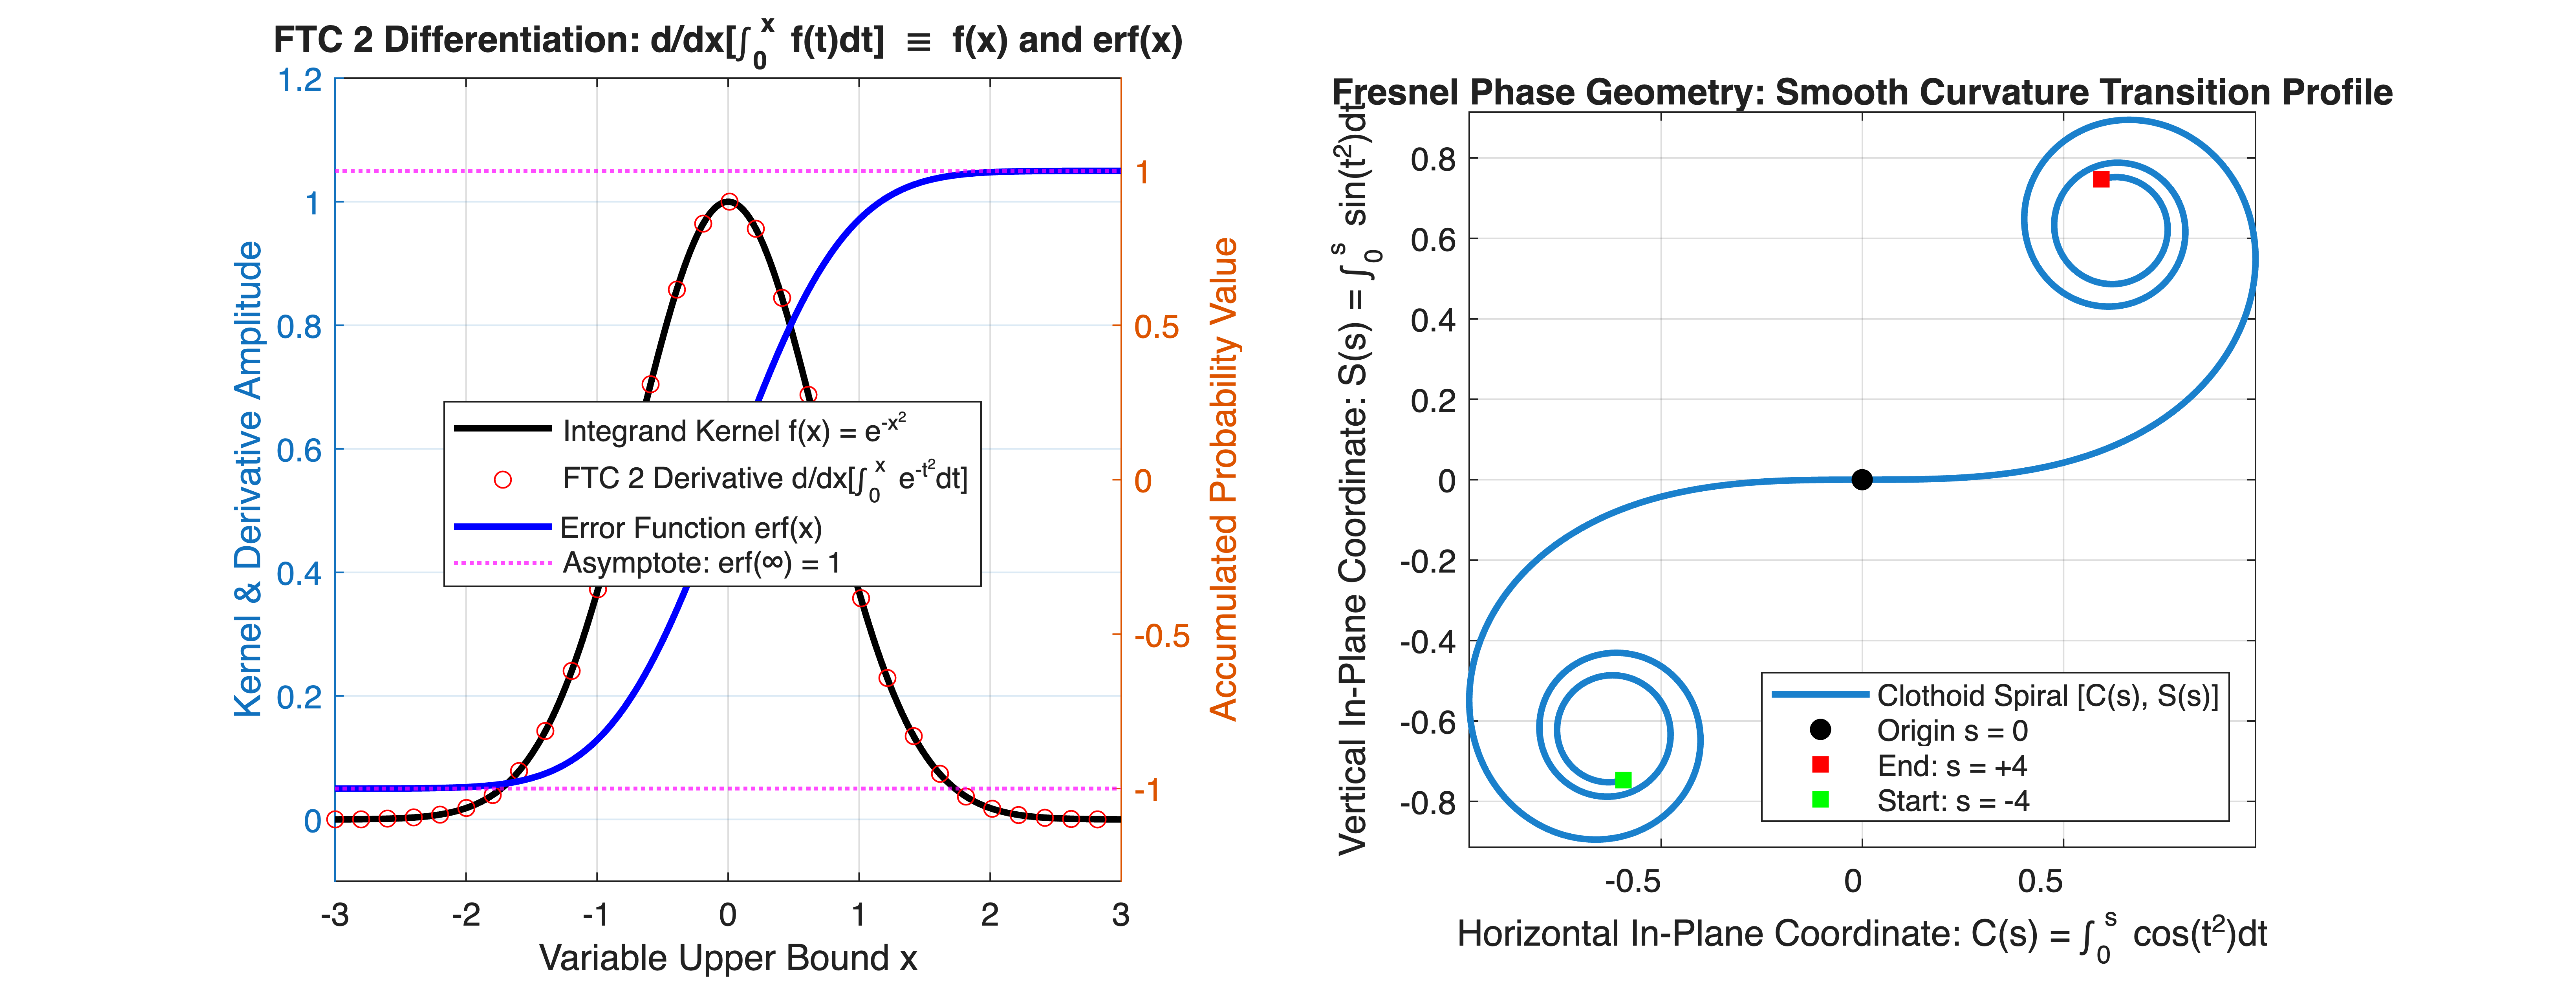

In [1]:
%% MIT 18.01 Lecture 20: Second Fundamental Theorem of Calculus & New Functions
% Mathematical Tool Application: Verifies operator inversion d/dx[\int_0^x f(t)dt] = f(x)
% for continuous integrator state equations, computes Gaussian error function CDF bounds,
% and generates Fresnel Euler spirals (Clothoids) for autonomous trajectory planning.


clear; clc; close all;


%% Part 1: Verification of FTC 2 & Error Function erf(x)
% Integrand function: f(t) = exp(-t^2)
f_kernel = @(t) exp(-t.^2);


% Variable upper limit x range: [-3, 3]
x_domain = linspace(-3.0, 3.0, 300);
F_accumulated = zeros(size(x_domain));


% Numerical integration of F(x) = \int_0^x exp(-t^2) dt
for k = 1:length(x_domain)
    xk = x_domain(k);
    if xk >= 0
        F_accumulated(k) = integral(f_kernel, 0, xk, 'RelTol', 1e-12, 'AbsTol', 1e-14);
    else
        F_accumulated(k) = -integral(f_kernel, xk, 0, 'RelTol', 1e-12, 'AbsTol', 1e-14);
    end
end


% Error function erf(x) = (2 / sqrt(pi)) * F(x)
erf_computed = (2.0 / sqrt(pi)) * F_accumulated;


% Numerical derivative of F(x) via central finite difference
dx = x_domain(2) - x_domain(1);
dF_dx_numerical = gradient(F_accumulated, dx);
f_exact_x = f_kernel(x_domain);


figure('Color', 'w', 'Position', [100, 100, 1250, 480]);


subplot(1, 2, 1);
yyaxis left;
plot(x_domain, f_exact_x, 'k-', 'LineWidth', 2.0, 'DisplayName', 'Integrand Kernel f(x) = e^{-x^2}'); hold on;
plot(x_domain(1:10:end), dF_dx_numerical(1:10:end), 'ro', 'MarkerSize', 5, ...
    'DisplayName', 'FTC 2 Derivative d/dx[\int_0^x e^{-t^2}dt]');
ylabel('Kernel & Derivative Amplitude');
ylim([-0.1, 1.2]);


yyaxis right;
plot(x_domain, erf_computed, 'b-', 'LineWidth', 2.0, 'DisplayName', 'Error Function erf(x)');
yline(1.0, 'm:', 'LineWidth', 1.2, 'DisplayName', 'Asymptote: erf(\infty) = 1');
yline(-1.0, 'm:', 'LineWidth', 1.2, 'HandleVisibility', 'off');
ylabel('Accumulated Probability Value');
ylim([-1.3, 1.3]);


grid on;
xlabel('Variable Upper Bound x');
title('FTC 2 Differentiation: d/dx[\int_0^x f(t)dt] \equiv f(x) and erf(x)');
legend('Location', 'northwest');


%% Part 2: Fresnel Integrals and Clothoid Trajectory (Euler Spiral)
% Fresnel Integrals: C(s) = \int_0^s cos(t^2) dt, S(s) = \int_0^s sin(t^2) dt
s_param = linspace(-4.0, 4.0, 600);
C_val = zeros(size(s_param));
S_val = zeros(size(s_param));


for i = 1:length(s_param)
    s_curr = s_param(i);
    if s_curr >= 0
        C_val(i) = integral(@(t) cos(t.^2), 0, s_curr, 'RelTol', 1e-10, 'AbsTol', 1e-12);
        S_val(i) = integral(@(t) sin(t.^2), 0, s_curr, 'RelTol', 1e-10, 'AbsTol', 1e-12);
    else
        C_val(i) = -integral(@(t) cos(t.^2), s_curr, 0, 'RelTol', 1e-10, 'AbsTol', 1e-12);
        S_val(i) = -integral(@(t) sin(t.^2), s_curr, 0, 'RelTol', 1e-10, 'AbsTol', 1e-12);
    end
end


subplot(1, 2, 2);
plot(C_val, S_val, 'Color', [0.1, 0.5, 0.8], 'LineWidth', 2.0, ...
    'DisplayName', 'Clothoid Spiral [C(s), S(s)]'); hold on;
plot(0, 0, 'ko', 'MarkerFaceColor', 'k', 'DisplayName', 'Origin s = 0');
plot(C_val(end), S_val(end), 'rs', 'MarkerFaceColor', 'r', 'DisplayName', 'End: s = +4');
plot(C_val(1), S_val(1), 'gs', 'MarkerFaceColor', 'g', 'DisplayName', 'Start: s = -4');


grid on; axis equal;
xlabel('Horizontal In-Plane Coordinate: C(s) = \int_0^s cos(t^2)dt');
ylabel('Vertical In-Plane Coordinate: S(s) = \int_0^s sin(t^2)dt');
title('Fresnel Phase Geometry: Smooth Curvature Transition Profile');
legend('Location', 'southeast');